# Business Insights Dashboard with AI Sales Prediction

## Notebook 04 - Model Training

### Objectives
- Import required libraries
- Load the cleaned dataset
- Perform feature engineering
- Train the Linear Regression model
- Evaluate the model
- Save the trained model using Joblib

In [25]:
# Data Manipulation
import pandas as pd
import numpy as np

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Model Evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Save Model
import joblib

In [26]:
df = pd.read_csv("../data/Sample - Superstore.csv", encoding="latin1")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [27]:
# Convert to datetime

df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

# Year

df["Year"] = df["Order Date"].dt.year

# Month

df["Month"] = df["Order Date"].dt.month

# Month Name

df["Month Name"] = df["Order Date"].dt.month_name()

# Shipping Days

df["Shipping Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

In [24]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Year',
       'Month', 'Month Name', 'Shipping Days'],
      dtype='str')

In [29]:
features = [
    "Category",
    "Sub-Category",
    "Ship Mode",
    "Region",
    "State",
    "Segment",
    "Quantity",
    "Discount",
    "Profit",
    "Year",
    "Month",
    "Shipping Days"
]

In [30]:
X = df[features]

y = df["Sales"]

In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [32]:
categorical_features = [
    "Category",
    "Sub-Category",
    "Region",
    "Segment",
    "Ship Mode",
    "State"
]

numerical_features = [
    "Quantity",
    "Discount",
    "Profit",
    "Year",
    "Month",
    "Shipping Days"
]

In [33]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "num",
            "passthrough",
            numerical_features
        )
    ]
)

In [34]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

In [35]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['Category','Sub-Category','Ship Mode',...,'Year','Month','Shipping Days']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of 

# Step 12: Model Evaluation

The trained model is evaluated on the test dataset.

Predictions are made on unseen data, and different evaluation metrics are calculated to measure the model's performance.

In [12]:
# Make predictions on the test dataset

y_pred = model.predict(X_test)

In [13]:
comparison = pd.DataFrame({
    "Actual Sales": y_test.values,
    "Predicted Sales": y_pred
})

comparison.head(10)

,Actual Sales,Predicted Sales
0,563.808,282.177653
1,36.672,13.168574
2,37.300,2.038885
3,212.058,413.216184
4,171.288,635.823960
5,99.136,56.292196
6,340.182,201.607275
7,17.380,-18.528660
8,22.620,34.796720
9,71.632,362.477028


## Mean Absolute Error (MAE)

MAE calculates the average absolute difference between the actual and predicted values.

A lower MAE indicates better model performance.

In [14]:
mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 2))

Mean Absolute Error (MAE): 199.06


## Mean Squared Error (MSE)

MSE calculates the average squared difference between actual and predicted values.

Larger errors receive a higher penalty because the differences are squared.

In [15]:
mse = mean_squared_error(y_test, y_pred)

print("Mean Squared Error (MSE):", round(mse, 2))

Mean Squared Error (MSE): 567797.3


In [16]:
rmse = np.sqrt(mse)

print("Root Mean Squared Error (RMSE):", round(rmse, 2))

Root Mean Squared Error (RMSE): 753.52


## R² Score

The R² Score measures how well the model explains the variation in the target variable.

The closer the value is to 1, the better the model fits the data.

In [17]:
r2 = r2_score(y_test, y_pred)

print("R² Score:", round(r2, 4))

R² Score: 0.0388


In [18]:
print("=" * 50)
print("MODEL EVALUATION")
print("=" * 50)

print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

MODEL EVALUATION
MAE  : 199.06
MSE  : 567797.30
RMSE : 753.52
R²   : 0.0388


In [36]:
from sklearn.ensemble import RandomForestRegressor

In [37]:
# Create Random Forest Pipeline

rf_model = Pipeline(

    steps=[

        ("preprocessor", preprocessor),

        ("regressor",
         RandomForestRegressor(
             n_estimators=100,
             random_state=42
         ))
    ]
)

In [38]:
rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['Category','Sub-Category','Ship Mode',...,'Year','Month','Shipping Days']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of 

# Random Forest Model Evaluation

In [39]:
# Make predictions on the test data

rf_predictions = rf_model.predict(X_test)

In [40]:
rf_comparison = pd.DataFrame({

    "Actual Sales": y_test.values,

    "Predicted Sales": rf_predictions

})

rf_comparison.head(10)

,Actual Sales,Predicted Sales
0,563.808,245.721380
1,36.672,34.332560
2,37.300,56.914960
3,212.058,485.859374
4,171.288,354.668410
5,99.136,65.844840
6,340.182,331.839584
7,17.380,17.840200
8,22.620,22.085880
9,71.632,138.996920


In [41]:
rf_mae = mean_absolute_error(y_test, rf_predictions)

print("Random Forest MAE :", round(rf_mae,2))

Random Forest MAE : 83.53


In [42]:
rf_mse = mean_squared_error(y_test, rf_predictions)

print("Random Forest MSE :", round(rf_mse,2))

Random Forest MSE : 237044.44


In [43]:
rf_rmse = np.sqrt(rf_mse)

print("Random Forest RMSE :", round(rf_rmse,2))

Random Forest RMSE : 486.87


In [44]:
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest R² :", round(rf_r2,4))

Random Forest R² : 0.5987


In [45]:
print("="*55)
print(" RANDOM FOREST MODEL EVALUATION ")
print("="*55)

print(f"MAE  : {rf_mae:.2f}")
print(f"MSE  : {rf_mse:.2f}")
print(f"RMSE : {rf_rmse:.2f}")
print(f"R²   : {rf_r2:.4f}")

 RANDOM FOREST MODEL EVALUATION 
MAE  : 83.53
MSE  : 237044.44
RMSE : 486.87
R²   : 0.5987


# Model Comparison

In [46]:
comparison_df = pd.DataFrame({

    "Metric": ["MAE","MSE","RMSE","R² Score"],

    "Linear Regression":[
        mae,
        mse,
        rmse,
        r2
    ],

    "Random Forest":[
        rf_mae,
        rf_mse,
        rf_rmse,
        rf_r2
    ]

})

comparison_df

,Metric,Linear Regression,Random Forest
0,MAE,199.063729,83.531644
1,MSE,567797.295254,237044.436915
2,RMSE,753.523255,486.872095
3,R² Score,0.038771,0.598705


# Model Comparison & Selection

Two regression algorithms were trained and evaluated.

1. Linear Regression
2. Random Forest Regressor

The evaluation metrics show that Random Forest performs significantly better than Linear Regression.

Therefore, Random Forest is selected as the final model for deployment in the Streamlit application.

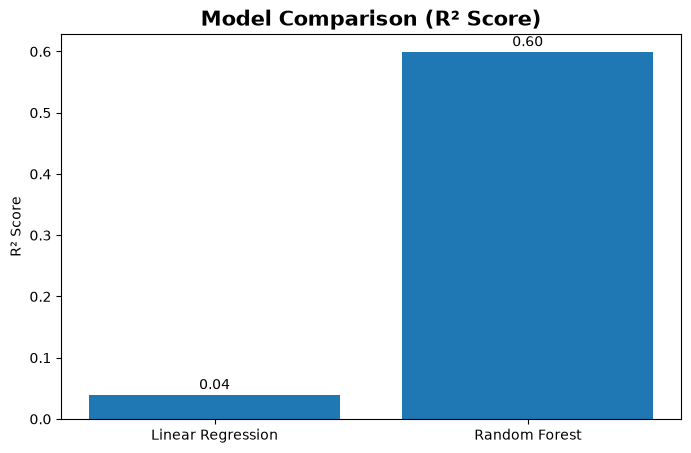

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.bar(
    ["Linear Regression", "Random Forest"],
    [r2, rf_r2]
)

plt.title("Model Comparison (R² Score)", fontsize=15, fontweight="bold")
plt.ylabel("R² Score")

for i, value in enumerate([r2, rf_r2]):
    plt.text(i, value + 0.01, f"{value:.2f}", ha="center")

plt.show()

# Model Persistence using Joblib

The best-performing model (Random Forest Regressor) is saved using Joblib.

This allows the trained model to be reused later in the Streamlit application without retraining.

In [48]:
import joblib

In [50]:
joblib.dump(rf_model, "../models/sales_model.pkl")

['../models/sales_model.pkl']

In [51]:
loaded_model = joblib.load("../models/sales_model.pkl")

In [52]:
print(type(loaded_model))

<class 'sklearn.pipeline.Pipeline'>


In [53]:
loaded_predictions = loaded_model.predict(X_test)

print("Original Model:")
print(rf_predictions[:5])

print()

print("Loaded Model:")
print(loaded_predictions[:5])

Original Model:
[245.72138   34.33256   56.91496  485.859374 354.66841 ]

Loaded Model:
[245.72138   34.33256   56.91496  485.859374 354.66841 ]
